# Subsequent arm injury in MLB pitchers: comparing three EWMA charts on fastball velocity (v4)

**Question.** Among pitchers returning from an arm IL placement, which of three control charts on
game-level fastball velocity best warns of a **subsequent arm IL placement** the same season?

1. **Velocity only, two-sided EWMA**: drifts in mean velocity either way (both lower and higher velocity
   than his pre-injury baseline were associated with higher risk in v3).
2. **Variability only, upper-sided EWMA on log CV**: fastball velocity becoming more variable.
3. **Max-EWMA**: one chart monitoring both, signalling on whichever component is more extreme.

**Units.** Each pitcher-season is its own unit (no carry-over between seasons): the first arm IL placement
of the season, first return by August 31, at least 5 post-return appearances. **Case**: the next non-COVID
IL placement that season is for the arm. **Control**: it is not (monitoring stops at a non-arm IL date) or
there is none. "Arm" = elbow, forearm, UCL / Tommy John, ulnar nerve, flexor / pronator, shoulder, rotator
cuff, labrum, biceps, triceps, lat / teres, thoracic outlet, capsule; not hand, finger, blister or wrist.

**Baseline.** Each pitcher's in-control mean (games in the 365 days before the initial injury, shrunk toward
his role's mean) and the pooled within-pitcher SD, both from training seasons.

**Evaluation.** All three charts are calibrated to the same false-alarm cost (the same share of control
games in alarm), λ is chosen by leave-one-season-out, and the main outcome is **early warning**: an arm IL
2–3 appearances after an alarm, with the injury game itself excluded.

**Held-out season.** 2026 was evaluated once in v3 with earlier chart designs, before this comparison was
specified (see Section 15). `RUN_HELDOUT` is off.

Outputs go to `data/arm_ewma_v4/`. Run top to bottom; all rules are in the Settings cell.

## 1. Settings

In [1]:
from pathlib import Path
import io
import re
import time
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

WORKSPACE = Path.cwd()
DATA_DIR = WORKSPACE / "data"
DATA_DIR.mkdir(exist_ok=True)
STATCAST_CACHE = DATA_DIR / "statcast"              # shared with the replication notebook
STATCAST_CACHE.mkdir(exist_ok=True)
CHADWICK_CACHE = DATA_DIR / "chadwick_register_ids.csv"
OUT_DIR = DATA_DIR / "arm_ewma_v4"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
INJURY_WORKBOOK = WORKSPACE / "MLB Injuries Raw Data.xlsx"
if not INJURY_WORKBOOK.exists():
    raise FileNotFoundError(f"Expected workbook was not found: {INJURY_WORKBOOK}")

# ---- Seasons ----
TRAIN_SEASONS = [2021, 2022, 2023, 2024, 2025]
TEST_SEASON = 2026                  # held out (evaluated once in v3 with earlier designs; see Section 15)
RUN_HELDOUT = False                 # keep False until the design is final
SEASONS = TRAIN_SEASONS + [TEST_SEASON]

# ---- Cohort rules ----
PITCHER_POSITIONS = {"RP", "SP", "SP/RP", "RP/SP", "P"}
FIRST_RETURN_CUTOFF = "08-31"       # first return by August 31 (as in the WHIP paper)
MIN_POST_RETURN_APPS = 5            # at least 5 post-return appearances (as in the WHIP paper)
PATTERNS = {
    "elbow": re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace", flags=re.IGNORECASE),
    "arm":   re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace|shoulder|rotator|labrum|\bbicep|\btricep|\barm\b|\blat\b|"
                        r"latissimus|teres|thoracic outlet|capsul", flags=re.IGNORECASE),
}
INITIAL_GROUP = "arm"               # "arm" or "elbow": which initial IL placements define the cohort
SUBSEQUENT_GROUP = "arm"            # "arm" or "elbow": which later placement counts as a case
OUTCOME_LABEL = SUBSEQUENT_GROUP    # used in figure titles
COVID_PATTERN = re.compile(r"covid", flags=re.IGNORECASE)

# ---- Game-level statistics ----
FASTBALLS = ["FF", "SI"]            # primary fastball = whichever he threw more before the injury
LOOKBACK_DAYS = 365                 # baseline window before the initial arm injury
MIN_FB_GAME = 8                     # a game needs >= 8 primary fastballs to give a mean / SD / CV
FIRST_N_FB = 20                     # sensitivity analysis: CV from the first 20 primary fastballs
REST_CAP = 10                       # (kept from v3; not used by the charts)
SHRINK_BY_ROLE = True               # shrink each pitcher toward his role's mean (starter / reliever / mixed)
MIN_UNITS_ROLE_FIT = 10             # a role needs >= 10 training units for its own fit (else league-wide)

# ---- Charts and evaluation ----
LAMS = np.round(np.arange(0.05, 0.951, 0.10), 2)   # λ grid: 0.05, 0.15, ..., 0.95
ALARM_RATE = 0.05                   # every chart is calibrated so 5% of control games are in alarm
K_LEAD = 3                          # early warning: subsequent IL 2..K_LEAD appearances after an alarm
N_BOOT = 1000                       # pitcher-clustered bootstrap resamples
SEED = 2026

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


print("Training seasons:", TRAIN_SEASONS, "| held-out season:", TEST_SEASON, "| RUN_HELDOUT =", RUN_HELDOUT)
print("Outputs:", OUT_DIR)

Training seasons: [2021, 2022, 2023, 2024, 2025] | held-out season: 2026 | RUN_HELDOUT = False
Outputs: /workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Pitcher Injuries/data/arm_ewma_v4


## 2. Injury records

Loads every season sheet, keeps pitcher rows with an IL date, and classifies each description as arm /
not arm and COVID / not COVID. Pitchers are keyed by **FanGraphs ID** rather than name, so accented
names cannot break the join (the issue behind the Table 2 baseline row). If a sheet has no
`key_fangraphs` column, the ID is read from the FanGraphs URL.

For the baseline window, the injury date is the **earlier** of the injury/surgery date and the IL date.
This matters for stints carried over from a previous season (e.g. Tommy John surgery the year before):
their IL date is opening day, but the pre-injury games are the ones before the surgery.

In [2]:
def clean_id(value):
    """IDs as plain strings: 12447.0 -> '12447', ' sa3012 ' -> 'sa3012'."""
    if pd.isna(value):
        return None
    text = str(value).strip()
    if not text:
        return None
    return text[:-2] if text.endswith(".0") else text


def fangraphs_id(row):
    value = clean_id(row.get("key_fangraphs"))
    if value:
        return value
    for column in ["URL", "sub_url"]:
        text = row.get(column)
        if isinstance(text, str):
            match = (re.search(r"/players/[^/]+/([^/?#]+)", text)
                     or re.match(r"[^/]+/([^/?#]+)/", text))
            if match:
                return match.group(1)
    return None


excel_file = pd.ExcelFile(INJURY_WORKBOOK)
tables = []
for sheet in excel_file.sheet_names:
    try:
        season = int(str(sheet).strip())
    except ValueError:
        continue
    if season in SEASONS:
        table = pd.read_excel(excel_file, sheet_name=sheet)
        table["Season"] = season
        tables.append(table)
missing_sheets = sorted(set(SEASONS) - {int(t["Season"].iloc[0]) for t in tables if len(t)})
if missing_sheets:
    raise ValueError(f"Workbook has no sheet for seasons {missing_sheets}")

injuries = pd.concat(tables, ignore_index=True).rename(columns={
    "IL Retro Date": "IL_Date", "Return Date": "Return_Date",
    "Injury / Surgery": "Injury", "Injury / Surgery Date": "Injury_Date"})
for column in ["IL_Date", "Return_Date", "Injury_Date"]:
    if column not in injuries.columns:
        injuries[column] = pd.NaT
    injuries[column] = pd.to_datetime(injuries[column], errors="coerce")

injuries["Pos"] = injuries["Pos"].astype(str).str.strip().str.upper()
injuries["Injury"] = injuries["Injury"].fillna("").astype(str).str.strip()
injuries["FanGraphs_ID"] = injuries.apply(fangraphs_id, axis=1)
injuries["pkey"] = injuries["FanGraphs_ID"].where(injuries["FanGraphs_ID"].notna(),
                                                  "name:" + injuries["Name"].astype(str))
injuries = injuries.loc[injuries["Pos"].isin(PITCHER_POSITIONS) & injuries["IL_Date"].notna()].copy()
injuries = injuries.drop_duplicates(["pkey", "Season", "IL_Date", "Injury"])
injuries["is_covid"] = injuries["Injury"].str.contains(COVID_PATTERN)
non_throwing = injuries["Injury"].str.contains("non-throwing", case=False)
for group, pattern in PATTERNS.items():
    injuries[f"is_{group}"] = injuries["Injury"].str.contains(pattern) & ~non_throwing
injuries["is_initial"] = injuries[f"is_{INITIAL_GROUP}"]
injuries["is_subseq"] = injuries[f"is_{SUBSEQUENT_GROUP}"]
injuries["onset"] = injuries[["Injury_Date", "IL_Date"]].min(axis=1)
injuries = injuries.sort_values(["pkey", "Season", "IL_Date"], kind="stable").reset_index(drop=True)

display(injuries.groupby("Season").agg(pitcher_IL_rows=("pkey", "size"),
                                      initial_type_rows=("is_initial", "sum"),
                                      subsequent_type_rows=("is_subseq", "sum"),
                                      covid_rows=("is_covid", "sum"),
                                      missing_fangraphs_id=("FanGraphs_ID", lambda s: int(s.isna().sum()))))

# Every description and how it was classified, for a line-by-line check of the rule.
classification_review = (injuries.loc[~injuries["is_covid"]]
                         .groupby(["is_arm", "is_elbow", "Injury"]).size().rename("IL rows").reset_index()
                         .sort_values(["is_arm", "is_elbow", "IL rows"], ascending=[False, False, False]))
classification_review.to_csv(OUT_DIR / "injury_classification_review.csv", index=False)
print(f"Initial injury group: {INITIAL_GROUP} | subsequent injury group: {SUBSEQUENT_GROUP}")
print("Arm descriptions (is_elbow marks the elbow subset):")
with pd.option_context("display.max_rows", 300):
    display(classification_review.loc[classification_review["is_arm"]])
print("Most common non-arm descriptions (full list in injury_classification_review.csv):")
display(classification_review.loc[~classification_review["is_arm"]].head(30))

,pitcher_IL_rows,initial_type_rows,subsequent_type_rows,covid_rows,missing_fangraphs_id
Season,,,,,
2021,687,303,303,130,0
2022,559,285,285,10,0
2023,502,293,293,2,0
2024,483,320,320,2,0
2025,458,292,292,0,0
2026,487,305,305,0,0


Initial injury group: arm | subsequent injury group: arm
Arm descriptions (is_elbow marks the elbow subset):


,is_arm,is_elbow,Injury,IL rows
517,True,True,Tommy John surgery,300
434,True,True,Elbow inflammation,158
511,True,True,Strained forearm,76
425,True,True,Elbow discomfort,34
505,True,True,Sprained elbow,33
462,True,True,Elbow surgery (internal brace),26
488,True,True,Forearm inflammation,26
506,True,True,Strained elbow,26
508,True,True,Strained elbow flexor,20
518,True,True,Tommy John surgery (internal brace),19


Most common non-arm descriptions (full list in injury_classification_review.csv):


,is_arm,is_elbow,Injury,IL rows
266,False,False,Strained oblique,122
256,False,False,Strained hamstring,104
255,False,False,Strained groin,82
310,False,False,Undisclosed,63
261,False,False,Strained lower back,51
247,False,False,Strained calf,38
144,False,False,Knee inflammation,33
227,False,False,Sprained ankle,24
126,False,False,Hip impingement,18
127,False,False,Hip inflammation,18


## 3. Cohort: initial arm IL placement → subsequent arm IL placement

For each pitcher-season, the **initial** placement is his first arm placement of that season. The
**next** non-COVID placement after his return decides the outcome: arm → case (chart runs up to that IL
date); anything else → control, chart stops at that IL date; none → control, chart runs to the end of the
season.

In [3]:
initial_rows = injuries.loc[injuries["is_initial"] & ~injuries["is_covid"]]
units = (initial_rows.groupby(["pkey", "Season"], as_index=False, sort=False).head(1)
              [["pkey", "Name", "Season", "FanGraphs_ID", "Team", "Pos", "Injury", "Injury_Date",
                "IL_Date", "onset", "Return_Date"]]
              .rename(columns={"Injury": "initial_injury"})
              .reset_index(drop=True))
funnel = [("Pitcher-seasons with an arm IL placement", len(units))]

cutoff = pd.to_datetime(units["Season"].astype(str) + "-" + FIRST_RETURN_CUTOFF)
units = units.loc[units["Return_Date"].notna()]
funnel.append(("... with a return date", len(units)))
units = units.loc[units["Return_Date"] >= units["IL_Date"]]
funnel.append(("... return on or after the IL date", len(units)))
units = units.loc[units["Return_Date"] <= cutoff.loc[units.index]].copy()
funnel.append((f"... first return by {FIRST_RETURN_CUTOFF}", len(units)))

# Next non-COVID IL placement after the return, same season.
later = injuries.loc[~injuries["is_covid"], ["pkey", "Season", "IL_Date", "Injury", "is_subseq"]].merge(
    units[["pkey", "Season", "Return_Date"]], on=["pkey", "Season"])
later = later.loc[later["IL_Date"] > later["Return_Date"]].sort_values(["pkey", "Season", "IL_Date"])
next_il = later.groupby(["pkey", "Season"], as_index=False).head(1)
any_later_subseq = later.loc[later["is_subseq"]].groupby(["pkey", "Season"]).size().rename("n_later_subseq")

units = units.merge(next_il[["pkey", "Season", "IL_Date", "Injury", "is_subseq"]]
                    .rename(columns={"IL_Date": "next_il_date", "Injury": "next_injury",
                                     "is_subseq": "next_is_subseq"}),
                    on=["pkey", "Season"], how="left")
units = units.merge(any_later_subseq, left_on=["pkey", "Season"], right_index=True, how="left")
units["next_is_subseq"] = units["next_is_subseq"].astype("boolean").fillna(False).astype(bool)
units["case"] = units["next_is_subseq"].astype(int)
units["event_date"] = units["next_il_date"].where(units["case"] == 1)
units["censor_date"] = units["next_il_date"].where(units["case"] == 0)
units["stop_date"] = units["next_il_date"].fillna(pd.to_datetime(units["Season"].astype(str) + "-12-31")
                                                  + pd.Timedelta(days=1))
units["outcome"] = np.select(
    [units["case"] == 1, units["censor_date"].notna()],
    ["case: subsequent arm IL", "control: stopped at non-arm IL"],
    default="control: no later IL")

n_subseq_after_other = int(((units["case"] == 0) & units["n_later_subseq"].notna()).sum())
print("Controls whose next placement was non-arm but who had an arm placement later that season:",
      n_subseq_after_other, "(kept as controls, as specified)")
display(pd.crosstab(units["Season"], units["outcome"], margins=True))

Controls whose next placement was non-arm but who had an arm placement later that season: 8 (kept as controls, as specified)


outcome,case: subsequent arm IL,control: no later IL,control: stopped at non-arm IL,All
Season,,,,
2021,32,75,22,129
2022,28,64,19,111
2023,23,74,19,116
2024,33,78,15,126
2025,27,63,17,107
2026,21,87,14,122
All,164,441,106,711


## 4. MLBAM IDs and Baseball Savant pitch data

Statcast uses MLBAM IDs, linked to FanGraphs IDs by the Chadwick register (cached by the replication
notebook; downloaded here if missing). Each pitcher's window runs from 365 days before the initial arm
injury to November 30 of the monitored season. Cached files from the replication notebook are used when
they cover the window; otherwise only the missing earlier dates are downloaded and cached as a separate
file.

In [4]:
CHADWICK_URL = "https://raw.githubusercontent.com/chadwickbureau/register/master/data/people-{}.csv"
if CHADWICK_CACHE.exists():
    id_map = pd.read_csv(CHADWICK_CACHE, dtype=str)
else:
    parts = []
    for suffix in "0123456789abcdef":
        part = pd.read_csv(CHADWICK_URL.format(suffix), usecols=["key_mlbam", "key_fangraphs"],
                           dtype=str, low_memory=False)
        parts.append(part.dropna())
        time.sleep(0.5)
    id_map = pd.concat(parts, ignore_index=True)
    id_map.to_csv(CHADWICK_CACHE, index=False)
fg_to_mlbam = dict(zip(id_map["key_fangraphs"].map(clean_id), id_map["key_mlbam"].map(clean_id)))

units["mlbam"] = units["FanGraphs_ID"].map(lambda v: fg_to_mlbam.get(v) if v else None)
no_id = units.loc[units["mlbam"].isna(), ["Name", "Season", "FanGraphs_ID"]]
if len(no_id):
    print("No MLBAM ID (dropped):")
    display(no_id)
units = units.loc[units["mlbam"].notna()].copy()
units["mlbam"] = units["mlbam"].astype(int)
funnel.append(("... with an MLBAM ID", len(units)))
units["window_start"] = (units["onset"] - pd.Timedelta(days=LOOKBACK_DAYS)).dt.normalize()
units["window_end"] = pd.to_datetime(units["Season"].astype(str) + "-11-30")
print("Pitcher-seasons to download:", len(units))

No MLBAM ID (dropped):


,Name,Season,FanGraphs_ID
604,Coleman Crow,2026,27926
605,Wilber Dotel,2026,28901
606,Kendry Rojas,2026,29423
628,Marco Raya,2026,30166
661,Tatsuya Imai,2026,37124
708,Dylan File,2021,sa3004197
709,Shane Drohan,2024,sa3014447
710,Daniel Tillo,2021,sa876284


Pitcher-seasons to download: 703


In [5]:
SAVANT_URL = (
    "https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=pitcher"
    "&hfGT=R%7C&hfSea=&game_date_gt={start}&game_date_lt={end}&pitchers_lookup%5B%5D={mlbam}"
    "&min_pitches=0&min_results=0&min_abs=0&group_by=name&sort_col=pitches&sort_order=desc"
)
SAVANT_KEEP = ["pitcher", "game_pk", "game_date", "game_type", "inning", "at_bat_number",
               "pitch_number", "pitch_type", "release_speed", "p_throws"]
CACHE_NAME = re.compile(r"(\d+)_(\d{8})_(\d{8})\.csv")


def download_statcast(mlbam, start, end, sleep_seconds=2.0, retries=3):
    """One Savant request (regular season), saved in the shared cache with the same file naming."""
    path = STATCAST_CACHE / f"{mlbam}_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path)
    url = SAVANT_URL.format(mlbam=mlbam, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}")
    for attempt in range(1, retries + 1):
        try:
            time.sleep(sleep_seconds)
            request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(request, timeout=120) as response:
                text = response.read().decode("utf-8-sig")
            break
        except Exception as error:
            print(f"  attempt {attempt} failed for {mlbam}: {error!r}")
            time.sleep(10 * attempt)
    else:
        raise RuntimeError(f"Could not download Statcast data for pitcher {mlbam}")
    data = pd.read_csv(io.StringIO(text)) if text.strip() else pd.DataFrame(columns=SAVANT_KEEP)
    required = set(SAVANT_KEEP) - {"p_throws"}
    if len(data) and required - set(data.columns):
        raise ValueError(f"Unexpected Savant response for {mlbam}: {text[:300]!r}")
    if "game_type" in data.columns:
        data = data.loc[data["game_type"] == "R"]
    data = data[[c for c in SAVANT_KEEP if c in data.columns]]
    data.to_csv(path, index=False)
    return data


def cached_files(mlbam):
    out = []
    for path in STATCAST_CACHE.glob(f"{mlbam}_*.csv"):
        match = CACHE_NAME.fullmatch(path.name)
        if match and int(match.group(1)) == mlbam:
            out.append((pd.Timestamp(match.group(2)), pd.Timestamp(match.group(3)), path))
    return out


def statcast_window(mlbam, start, end):
    """Pitches for [start, end], from the cache where possible; downloads only the uncovered part."""
    files = cached_files(mlbam)
    pieces = [pd.read_csv(p) for s, e, p in files if s <= end and e >= start]   # overlapping files
    covered_from = min([s for s, e, p in files if s <= end and e >= end], default=None)
    if covered_from is None:                       # nothing reaches the end date: one full request
        pieces.append(download_statcast(mlbam, start, end))
    elif covered_from > start:                     # fetch only the earlier, uncovered dates
        pieces.append(download_statcast(mlbam, start, covered_from - pd.Timedelta(days=1)))
    pieces = [p for p in pieces if len(p)]
    if not pieces:
        return pd.DataFrame(columns=SAVANT_KEEP)
    data = pd.concat(pieces, ignore_index=True)
    data["game_date"] = pd.to_datetime(data["game_date"])
    return data.loc[data["game_date"].between(start, end)]


pieces, statcast_failures = [], []
for number, (_, row) in enumerate(units.drop_duplicates(["mlbam", "window_start", "window_end"]).iterrows(), 1):
    try:
        pieces.append(statcast_window(row["mlbam"], row["window_start"], row["window_end"]))
    except Exception as error:
        statcast_failures.append({"Name": row["Name"], "Season": row["Season"], "mlbam": row["mlbam"],
                                  "error": repr(error)})
    if number % 50 == 0:
        print(f"{number} windows ({len(statcast_failures)} failures)")
statcast_failures = pd.DataFrame(statcast_failures)
statcast_failures.to_csv(OUT_DIR / "statcast_fetch_failures.csv", index=False)
if len(statcast_failures):
    display(statcast_failures)

pitches = pd.concat(pieces, ignore_index=True)
if "p_throws" not in pitches.columns:
    pitches["p_throws"] = np.nan
pitches = pitches.dropna(subset=["game_pk", "at_bat_number", "pitch_number"]).copy()
pitches["pitcher"] = pitches["pitcher"].astype(int)
pitches["game_pk"] = pitches["game_pk"].astype(int)
pitches["game_date"] = pd.to_datetime(pitches["game_date"])
pitches = (pitches.drop_duplicates(["pitcher", "game_pk", "at_bat_number", "pitch_number"])
                  .sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
                  .reset_index(drop=True))
pitches["pitch_count"] = pitches.groupby(["pitcher", "game_pk"]).cumcount() + 1
pitches_by_pitcher = {p: g for p, g in pitches.groupby("pitcher")}
print(f"Pitches: {len(pitches):,} | pitchers: {pitches['pitcher'].nunique()}")

50 windows (2 failures)
100 windows (4 failures)
150 windows (6 failures)
200 windows (10 failures)
250 windows (17 failures)
300 windows (20 failures)
350 windows (23 failures)
400 windows (31 failures)
450 windows (35 failures)
500 windows (46 failures)
550 windows (60 failures)
600 windows (63 failures)
650 windows (69 failures)
700 windows (75 failures)


,Name,Season,mlbam,error
0,Mike Minor,2022,501985,"NotImplementedError(""strftime not yet supporte..."
1,Tommy Kahnle,2023,592454,"NotImplementedError(""strftime not yet supporte..."
2,Dylan Floro,2022,571670,"NotImplementedError(""strftime not yet supporte..."
3,Lucas Sims,2022,608371,"NotImplementedError(""strftime not yet supporte..."
4,Josh Hader,2026,623352,"NotImplementedError(""strftime not yet supporte..."
...,...,...,...,...
70,Jay Jackson,2022,543351,"NotImplementedError(""strftime not yet supporte..."
71,Justin Verlander,2024,434378,"NotImplementedError(""strftime not yet supporte..."
72,Wade Miley,2022,489119,"NotImplementedError(""strftime not yet supporte..."
73,Wade Miley,2024,489119,"NotImplementedError(""strftime not yet supporte..."


Pitches: 999,047 | pitchers: 482


In [6]:
# Arm descriptions that name a side: flag any that do not match the throwing arm, for manual review.
throws = pitches.dropna(subset=["p_throws"]).groupby("pitcher")["p_throws"].agg(lambda s: s.mode().iat[0])
units["throws"] = units["mlbam"].map(throws)
side = units["initial_injury"].str.extract(r"\b(left|right)\b", flags=re.IGNORECASE, expand=False).str.upper().str[0]
side_check = units.assign(side=side).loc[lambda d: d["side"].notna()]
mismatch = side_check.loc[side_check["throws"].notna() & (side_check["side"] != side_check["throws"])]
print(f"Initial arm descriptions naming a side: {len(side_check)}; "
      f"side differs from the throwing arm: {len(mismatch)}")
if len(mismatch):
    display(mismatch[["Name", "Season", "initial_injury", "throws"]])

Initial arm descriptions naming a side: 0; side differs from the throwing arm: 0


## 5. Game-level fastball statistics

For each unit:

* **Primary fastball**: FF or SI, whichever he threw more in the 365 days before the injury (if he has no
  pre-injury fastballs, the post-return games decide).
* **Baseline games**: games in that pre-injury window with at least `MIN_FB_GAME` primary fastballs.
* **Monitored games**: games from the return date up to (not including) the stop date, with at least
  `MIN_FB_GAME` primary fastballs. Appearances with fewer fastballs leave the chart unchanged.
* **Post-return appearances** (for the 5-appearance rule) count every regular-season game after the return
  that season, as in the WHIP paper.
* **Per-game statistics**: mean, SD and CV (= 100 × SD / mean) of primary-fastball velocity, and for the
  sensitivity analyses the CV of the first `FIRST_N_FB` fastballs and the CV of residuals around the game's
  own linear fade. Types are forced to numeric, which avoids the object-dtype `log` error.

In [7]:
def per_game(game_pitches, primary):
    """One row per game for the primary fastball: count, mean, SD, CV, plus two CV variants for the
    sensitivity analyses (first FIRST_N_FB fastballs; residuals around the game's own linear fade),
    and the logs of the three CVs. Games with fewer than MIN_FB_GAME primary fastballs are dropped."""
    cols = ["game_pk", "game_date", "n_fb", "velo", "sd", "cv", "cv_f20", "cv_resid", "n_pitches",
            "logcv", "logcv_f20", "logcv_resid"]
    fb = game_pitches.loc[game_pitches["pitch_type"] == primary,
                          ["game_pk", "game_date", "pitch_count", "release_speed"]].copy()
    fb["release_speed"] = pd.to_numeric(fb["release_speed"], errors="coerce").astype(float)
    fb["pitch_count"] = pd.to_numeric(fb["pitch_count"], errors="coerce").astype(float)
    fb = fb.dropna(subset=["release_speed", "pitch_count"])
    if fb.empty:
        return pd.DataFrame({c: pd.Series(dtype=float) for c in cols})
    grp = fb.groupby("game_pk")
    g = grp.agg(game_date=("game_date", "first"), n_fb=("release_speed", "size"),
                velo=("release_speed", "mean"), sd=("release_speed", "std")).reset_index()
    f20 = fb.groupby("game_pk", sort=False).head(FIRST_N_FB).groupby("game_pk")["release_speed"].agg(["mean", "std"])
    g["cv_f20"] = g["game_pk"].map(100 * f20["std"] / f20["mean"])
    xd = fb["pitch_count"] - grp["pitch_count"].transform("mean")
    yd = fb["release_speed"] - grp["release_speed"].transform("mean")
    slope = ((xd * yd).groupby(fb["game_pk"]).sum() / (xd ** 2).groupby(fb["game_pk"]).sum().replace(0, np.nan)).fillna(0)
    resid = yd - fb["game_pk"].map(slope) * xd
    sd_resid = np.sqrt((resid ** 2).groupby(fb["game_pk"]).sum() / (grp.size() - 2).clip(lower=1))
    g["cv"] = 100 * g["sd"] / g["velo"]
    g["cv_resid"] = 100 * g["game_pk"].map(sd_resid) / g["velo"]
    g["n_pitches"] = g["game_pk"].map(game_pitches.groupby("game_pk").size())
    g = g.loc[g["n_fb"] >= MIN_FB_GAME].sort_values(["game_date", "game_pk"]).reset_index(drop=True)
    for c in ["n_fb", "velo", "sd", "cv", "cv_f20", "cv_resid", "n_pitches"]:
        g[c] = pd.to_numeric(g[c], errors="coerce").astype(float)
    for c in ["cv", "cv_f20", "cv_resid"]:
        g["log" + c] = np.log(np.clip(g[c].to_numpy(float), 1e-6, None))
    return g[cols]


unit_data, drop_reason = {}, {}
units = units.reset_index(drop=True)
units["uid"] = units.index
for _, row in units.iterrows():
    g = pitches_by_pitcher.get(row["mlbam"])
    if g is None:
        drop_reason[row["uid"]] = "no Statcast pitches"
        continue
    season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
    pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
    post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)]
    monitored_raw = post.loc[post["game_date"] < row["stop_date"]]

    fb_counts = pre.loc[pre["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        fb_counts = monitored_raw.loc[monitored_raw["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        drop_reason[row["uid"]] = "no four-seam or sinker"
        continue
    primary = fb_counts.idxmax()

    apps = post.drop_duplicates("game_pk")[["game_pk", "game_date"]].sort_values(["game_date", "game_pk"])
    if len(apps) < MIN_POST_RETURN_APPS:
        drop_reason[row["uid"]] = f"fewer than {MIN_POST_RETURN_APPS} post-return appearances"
        continue
    apps_before_stop = apps.loc[apps["game_date"] < row["stop_date"]].reset_index(drop=True)
    monitored = per_game(monitored_raw, primary)
    if monitored.empty:
        drop_reason[row["uid"]] = "no monitored game with enough fastballs"
        continue
    pre_games = pre.groupby("game_pk")["inning"].min()
    ref_games = pre_games if len(pre_games) else monitored_raw.groupby("game_pk")["inning"].min()
    start_share = (ref_games == 1).mean() if len(ref_games) else np.nan
    role = ("unknown" if np.isnan(start_share) else "starter" if start_share >= 0.6
            else "reliever" if start_share <= 0.2 else "mixed")
    app_index = {pk: i for i, pk in enumerate(apps_before_stop["game_pk"])}
    monitored["app_index"] = monitored["game_pk"].map(app_index)      # 0 = first appearance back
    rest = apps_before_stop["game_date"].diff().dt.days.fillna(REST_CAP)   # first game back = long rest
    monitored["rest_days"] = monitored["game_pk"].map(dict(zip(apps_before_stop["game_pk"], rest)))
    unit_data[row["uid"]] = {
        "primary": primary,
        "role": role,
        "baseline": per_game(pre, primary),
        "monitored": monitored,
        "n_apps_before_stop": len(apps_before_stop),
        "n_post_return_apps": len(apps),
    }

units["dropped"] = units["uid"].map(drop_reason)
for reason, n in units["dropped"].value_counts().items():
    print(f"Dropped: {reason}: {n}")
units = units.loc[units["dropped"].isna()].drop(columns="dropped")   # index stays = uid
funnel.append((f"... with Statcast data, >= {MIN_POST_RETURN_APPS} post-return appearances, "
               "and >= 1 monitored game", len(units)))
units["split"] = np.where(units["Season"].isin(TRAIN_SEASONS), "train", "test")
units["primary"] = units["uid"].map(lambda u: unit_data[u]["primary"])
units["role"] = units["uid"].map(lambda u: unit_data[u]["role"])
units["baseline_games"] = units["uid"].map(lambda u: len(unit_data[u]["baseline"]))
units["monitored_games"] = units["uid"].map(lambda u: len(unit_data[u]["monitored"]))

funnel = pd.DataFrame(funnel, columns=["step", "pitcher-seasons"])
funnel.to_csv(OUT_DIR / "cohort_funnel.csv", index=False)
display(funnel)
cohort_table = (units.groupby(["split", "Season"])
                     .agg(units=("uid", "size"), cases=("case", "sum"),
                          controls_stopped_at_other_IL=("censor_date", lambda s: int(s.notna().sum())),
                          median_baseline_games=("baseline_games", "median"),
                          no_baseline_games=("baseline_games", lambda s: int((s == 0).sum())),
                          median_monitored_games=("monitored_games", "median")))
display(cohort_table)
display(pd.crosstab([units["split"], units["role"]], units["case"].map({1: "case", 0: "control"})))
units.drop(columns=["window_start", "window_end"]).to_csv(OUT_DIR / "cohort_units.csv", index=False)

Dropped: fewer than 5 post-return appearances: 124
Dropped: no Statcast pitches: 46
Dropped: no four-seam or sinker: 23
Dropped: no monitored game with enough fastballs: 22


,step,pitcher-seasons
0,Pitcher-seasons with an arm IL placement,1590
1,... with a return date,1284
2,... return on or after the IL date,1283
3,... first return by 08-31,711
4,... with an MLBAM ID,703
5,"... with Statcast data, >= 5 post-return appea...",488


units  cases  controls_stopped_at_other_IL  \
split Season                                               
test  2026       84     12                            13   
train 2021       88     20                            16   
      2022       78     19                            15   
      2023       77     15                            14   
      2024       82     21                            10   
      2025       79     22                            11   

              median_baseline_games  no_baseline_games  median_monitored_games  
split Season                                                                    
test  2026                     19.0                  2                     9.0  
train 2021                     14.0                  3                     7.5  
      2022                     19.0                  1                     8.0  
      2023                     19.0                  5                     8.0  
      2024                     20.5                  4                     8.0  
      2025                     19.0                  5                     8.0

case            case  control
split role                   
test  mixed        0        1
      reliever     7       44
      starter      5       27
train mixed        8       10
      reliever    47      162
      starter     42      135

## 6. Baselines: role-shrunk pre-injury mean and SD (training seasons only)

For each statistic (game mean velocity; log CV and its two variants), the grand mean $G$, the pooled
within-pitcher SD $\sigma_0$ (ANOVA $SS_W/df_W$) and the shrinkage weight $k=\sigma^2_w/\sigma^2_b$
(Henderson's Method I) are estimated from the **baseline games of training-season units**, separately for
starters, relievers and mixed-role pitchers. Each unit's in-control mean is

$$\mu_0 = \frac{n_i \bar x_i + k G}{n_i + k},$$

from his own $n_i$ baseline games (365 days before the initial arm injury); no baseline games → $\mu_0 = G$.
Every monitored game is then standardized: $z_j = (x_j - \mu_0)/\sigma_0$. Held-out units use the frozen
training $G$, $k$, $\sigma_0$ with their own pre-injury games.

In [8]:
def fit_shrinkage(frames, value):
    """Henderson Method I on baseline games: grand mean, pooled within SD, shrinkage weight k."""
    y = [f[value].dropna().to_numpy(float) for f in frames]
    y = [v for v in y if len(v) >= 1]
    n = np.array([len(v) for v in y], float)
    N, a = n.sum(), len(y)
    grand = np.concatenate(y).mean()
    means = np.array([v.mean() for v in y])
    ms_w = sum(((v - v.mean()) ** 2).sum() for v in y) / (N - a)
    ms_b = (n * (means - grand) ** 2).sum() / (a - 1)
    n0 = (N - (n ** 2).sum() / N) / (a - 1)
    var_b = max((ms_b - ms_w) / n0, 0.0)
    return {"grand_mean": grand, "sigma_w": np.sqrt(ms_w), "sigma_b": np.sqrt(var_b),
            "k": ms_w / var_b if var_b > 0 else np.inf, "units": a, "games": int(N)}


def shrunk_mean(baseline, value, fit):
    x = baseline[value].dropna()
    if len(x) == 0 or not np.isfinite(fit["k"]):
        return fit["grand_mean"]
    return (len(x) * x.mean() + fit["k"] * fit["grand_mean"]) / (len(x) + fit["k"])


toy = [pd.DataFrame({"x": [1.0, 2.0, 3.0]}), pd.DataFrame({"x": [3.0, 2.0, 1.0]})]
assert fit_shrinkage(toy, "x")["k"] == np.inf and abs(fit_shrinkage(toy, "x")["sigma_w"] - 1) < 1e-12

train_uids = units.loc[units["split"] == "train", "uid"].tolist()
test_uids = units.loc[units["split"] == "test", "uid"].tolist()
all_uids = units["uid"].tolist()


def role_fits(frames, stat):
    """Fit on training units: one fit per role with >= MIN_UNITS_ROLE_FIT units, else league-wide."""
    f_all = fit_shrinkage([frames[u] for u in train_uids], stat)
    f_role = {}
    for role in ["starter", "reliever", "mixed"]:
        ru = [u for u in train_uids if unit_data[u]["role"] == role and frames[u][stat].notna().any()]
        if SHRINK_BY_ROLE and len(ru) >= MIN_UNITS_ROLE_FIT:
            f_role[role] = fit_shrinkage([frames[u] for u in ru], stat)
    table = pd.DataFrame({"all": f_all, **f_role}).T
    return (lambda u: f_role.get(unit_data[u]["role"], f_all)), table


def build_inputs(cv_stat="logcv", min_fb=MIN_FB_GAME, post_return_n=0):
    """Per-unit standardized game series for the charts.
    cv_stat: 'logcv' (main), 'logcv_f20' (first FIRST_N_FB fastballs) or 'logcv_resid' (fade removed).
    post_return_n > 0: baseline = his first post_return_n monitored games instead (monitoring starts after)."""
    base = {u: unit_data[u]["baseline"].loc[lambda d: d["n_fb"] >= min_fb].dropna(subset=["velo", cv_stat])
            for u in all_uids}
    mon = {u: unit_data[u]["monitored"].loc[lambda d: d["n_fb"] >= min_fb].dropna(subset=["velo", cv_stat])
           for u in all_uids}
    fv, tab_v = role_fits(base, "velo")
    fc, tab_c = role_fits(base, cv_stat)
    V = {}
    for u in all_uids:
        m = mon[u]
        if post_return_n:
            if len(m) <= post_return_n:
                continue
            mu_v, mu_c = m["velo"].iloc[:post_return_n].mean(), m[cv_stat].iloc[:post_return_n].mean()
            m = m.iloc[post_return_n:]
        else:
            if m.empty:
                continue
            mu_v, mu_c = shrunk_mean(base[u], "velo", fv(u)), shrunk_mean(base[u], cv_stat, fc(u))
        sv, sc = fv(u)["sigma_w"], fc(u)["sigma_w"]
        V[u] = {"velo": (m["velo"].to_numpy(float) - mu_v) / sv,
                "cv": (m[cv_stat].to_numpy(float) - mu_c) / sc,
                "back": unit_data[u]["n_apps_before_stop"] - m["app_index"].to_numpy(),
                "app_index": m["app_index"].to_numpy(), "date": m["game_date"].to_numpy(),
                "raw_velo": m["velo"].to_numpy(float), "raw_cv": m["cv"].to_numpy(float),
                "mu_v": mu_v, "sig_v": sv, "mu_c": mu_c, "sig_c": sc}
    return V, pd.concat({"velocity": tab_v, cv_stat: tab_c}, names=["statistic", "fit"])


V_MAIN, baseline_table = build_inputs("logcv")
baseline_table.to_csv(OUT_DIR / "baseline_fits.csv")
display(baseline_table.round(4))
print(f"Units with a monitored series: {len(V_MAIN)} "
      f"({sum(u in V_MAIN for u in train_uids)} training, {sum(u in V_MAIN for u in test_uids)} held-out)")

grand_mean  sigma_w  sigma_b       k  units   games
statistic fit                                                          
velocity  all          94.4530   0.7736   2.4388  0.1006  386.0  7501.0
          starter      93.4598   0.7428   2.2371  0.1103  171.0  3513.0
          reliever     95.4300   0.7874   2.2821  0.1190  197.0  3672.0
          mixed        94.1419   0.9338   1.8601  0.2520   18.0   316.0
logcv     all          -0.1272   0.2452   0.2346  1.0924  386.0  7501.0
          starter       0.0233   0.1994   0.1804  1.2218  171.0  3513.0
          reliever     -0.2767   0.2829   0.1859  2.3161  197.0  3672.0
          mixed        -0.0614   0.2361   0.1701  1.9270   18.0   316.0

Units with a monitored series: 488 (404 training, 84 held-out)


## 7. Descriptive check: the two standardized statistics before a subsequent arm IL

Training seasons. **Left:** cases lined up by games **before** the subsequent IL (1 = final game), against
the controls' average monitored game (grey band). **Right:** cases and controls lined up by games **since
return**, to tell a pre-injury change from what every returning pitcher does. Mean ± 95% CI.

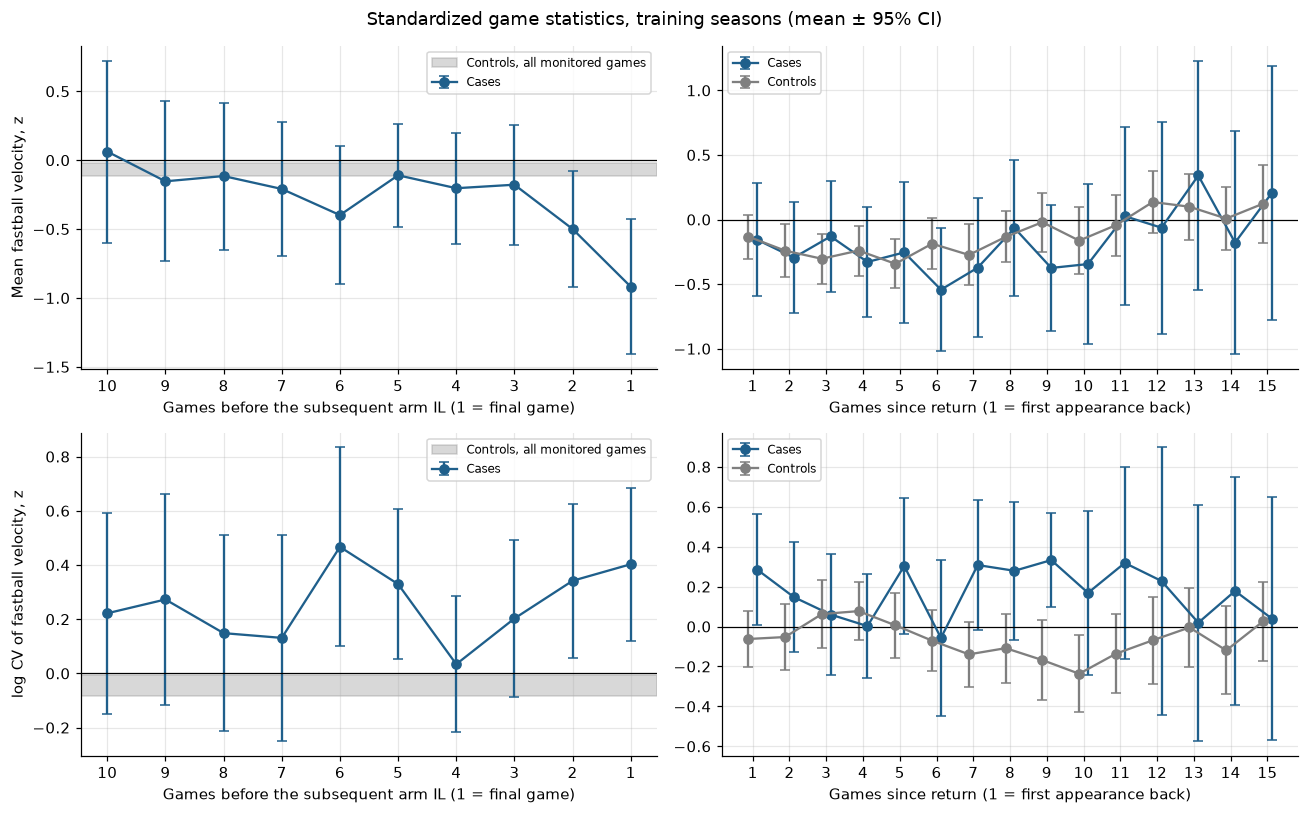

In [9]:
def series_frame(V, uids, key):
    return pd.concat([pd.DataFrame({"uid": u, "case": int(units.at[u, "case"]), "z": V[u][key],
                                    "back": V[u]["back"], "since": V[u]["app_index"] + 1})
                      for u in uids if u in V], ignore_index=True)


fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), squeeze=False)
for row, (key, label) in enumerate([("velo", "Mean fastball velocity, z"), ("cv", "log CV of fastball velocity, z")]):
    df = series_frame(V_MAIN, train_uids, key)
    ax = axes[row, 0]
    ctrl = df.loc[df["case"] == 0, "z"]
    ax.axhspan(ctrl.mean() - 1.96 * ctrl.sem(), ctrl.mean() + 1.96 * ctrl.sem(), color="grey", alpha=0.3,
               label="Controls, all monitored games")
    s = df.loc[(df["case"] == 1) & (df["back"] <= 10)].groupby("back")["z"].agg(["mean", "sem"]).reindex(range(1, 11))
    ax.errorbar(s.index, s["mean"], yerr=1.96 * s["sem"], fmt="o-", capsize=3, color="#1f5f8b", label="Cases")
    ax.invert_xaxis(); ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(1, 11)); ax.set_xlabel("Games before the subsequent arm IL (1 = final game)")
    ax.set_ylabel(label); ax.legend(fontsize=8)
    ax = axes[row, 1]
    for grp, color in [(1, "#1f5f8b"), (0, "#7f7f7f")]:
        s = df.loc[(df["case"] == grp) & (df["since"] <= 15)].groupby("since")["z"].agg(["mean", "sem"]).reindex(range(1, 16))
        ax.errorbar(s.index + (0.12 if grp else -0.12), s["mean"], yerr=1.96 * s["sem"], fmt="o-", capsize=3,
                    color=color, label="Cases" if grp else "Controls")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(1, 16)); ax.set_xlabel("Games since return (1 = first appearance back)")
    ax.legend(fontsize=8)
fig.suptitle("Standardized game statistics, training seasons (mean ± 95% CI)")
fig.tight_layout()
save(fig, "F1_descriptive")

## 8. The three charts

All three are classical EWMA charts (no reset) on the standardized game series, with exact time-varying
limits. For game $j$ after return:

$$Z_j = \lambda z_j + (1-\lambda) Z_{j-1},\quad Z_0 = 0,\qquad
s_j = \sqrt{\tfrac{\lambda}{2-\lambda}\left[1-(1-\lambda)^{2j}\right]}$$

| Chart | Statistic plotted | Signals when | Parameters |
|---|---|---|---|
| **1. Velocity, two-sided EWMA** | $\lvert Z^{v}_j \rvert / s_j$ | velocity drifts **either** way: $> L_1$ | $\lambda_1, L_1$ |
| **2. Variability, upper-sided EWMA on log CV** | $\max(Z^{c}_j, 0)/s_j$ | fastball velocity becomes **more variable**: $> L_2$ | $\lambda_2, L_2$ |
| **3. Max-EWMA** | $M_j = \max\left(\lvert Z^{v}_j\rvert,\ \max(Z^{c}_j,0)\right)/s_j$, shared $\lambda$ | either component: $> L_3$ | $\lambda_3, L_3$ |

**Why log CV, and why upper-sided.** Game CV is right-skewed; its log is close to normal, which the EWMA
limits assume and which puts the variability component on the same footing as velocity in the Max-EWMA.
Lower variability (a more consistent pitcher) is not a hazard, so the variability charts are one-sided.

**Limits.** If the standardized series were independent N(0, 1), $L = 1.96$ (chart 1), $1.645$ (chart 2)
and $L_3$ solving $(2\Phi(L)-1)\Phi(L) = 0.95$ would each put 5% of in-control games in alarm. Real game
series are serially correlated and baselines are estimated, so the **primary** analysis calibrates each
chart's $L$ empirically on control games (Section 9); the theoretical limits are reported as a check.

The cell checks the EWMA recursion and that, on simulated independent N(0, 1) data, each standardized
statistic alarms 5% of the time at the theoretical limit.

In [10]:
from math import erf, sqrt


def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))


def solve_L_max(rate=0.05):
    lo, hi = 1.0, 5.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if (2 * Phi(mid) - 1) * Phi(mid) < 1 - rate else (lo, mid)
    return (lo + hi) / 2


def solve_two_sided(rate):
    lo, hi = 0.0, 6.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if 2 * (1 - Phi(mid)) > rate else (lo, mid)
    return (lo + hi) / 2


def solve_one_sided(rate):
    lo, hi = 0.0, 6.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if 1 - Phi(mid) > rate else (lo, mid)
    return (lo + hi) / 2


L_THEORY = {"velocity": solve_two_sided(ALARM_RATE), "variability": solve_one_sided(ALARM_RATE),
            "max": solve_L_max(ALARM_RATE)}


def ewma(z, lam):
    out = np.empty(len(z))
    prev = 0.0
    for j, x in enumerate(z):
        prev = lam * x + (1 - lam) * prev
        out[j] = prev
    return out


def ewma_sd(n, lam):
    j = np.arange(1, n + 1)
    return np.sqrt(lam / (2 - lam) * (1 - (1 - lam) ** (2 * j)))


CHARTS = ["velocity", "variability", "max"]
CHART_LABEL = {"velocity": "1. Velocity, two-sided EWMA", "variability": "2. log CV, upper-sided EWMA",
               "max": "3. Max-EWMA (velocity, log CV)"}
CHART_SHORT = {"velocity": "1. Velocity", "variability": "2. log CV", "max": "3. Max-EWMA"}
SHORT_OF_LABEL = {CHART_LABEL[c]: CHART_SHORT[c] for c in CHART_LABEL}


def chart_statistic(Vu, chart, lam):
    """Returns (plotted statistic, component): component = +1/-1 velocity high/low, 2 = variability."""
    s = ewma_sd(len(Vu["velo"]), lam)
    zv, zc = ewma(Vu["velo"], lam) / s, np.maximum(ewma(Vu["cv"], lam), 0) / s
    if chart == "velocity":
        return np.abs(zv), np.sign(zv)
    if chart == "variability":
        return zc, np.full(len(zc), 2.0)
    m = np.maximum(np.abs(zv), zc)
    return m, np.where(zc > np.abs(zv), 2.0, np.sign(zv))


# Checks
np.testing.assert_allclose(ewma([1, 0, 0], 0.5), [0.5, 0.25, 0.125])
sim = np.random.default_rng(1).standard_normal((20000, 30))
for lam in (0.1, 0.5, 0.9):
    s = ewma_sd(30, lam)
    Zv = np.apply_along_axis(ewma, 1, sim, lam) / s
    Zc = np.maximum(np.apply_along_axis(ewma, 1, sim[:, ::-1], lam), 0) / s     # an independent series
    assert abs((np.abs(Zv) > L_THEORY["velocity"]).mean() - 0.05) < 0.005
    assert abs((Zc > L_THEORY["variability"]).mean() - 0.05) < 0.005
    assert abs((np.maximum(np.abs(Zv), Zc) > L_THEORY["max"]).mean() - 0.05) < 0.006
print("EWMA checks passed. Theoretical limits for", f"{ALARM_RATE:.0%} per-game alarms:",
      {k: round(v, 3) for k, v in L_THEORY.items()})

EWMA checks passed. Theoretical limits for 5% per-game alarms: {'velocity': 1.96, 'variability': 1.645, 'max': 2.123}


## 9. Comparing the three charts (training seasons, leave-one-season-out)

The same procedure for every chart, so they are compared at the **same false-alarm cost**:

1. Leave one training season out. On the other seasons, for each λ in `LAMS`, set $L$ so that
   `ALARM_RATE` of **control** games are in alarm, and pick the λ with the most alarms in case games 2 to
   `K_LEAD` appearances before the subsequent IL (early warning).
2. Apply that λ and $L$ to the left-out season. Pool the left-out seasons.

**Reported** (all pooled over left-out seasons):

* **Early warning**: share of case games 2–`K_LEAD` before the IL in alarm, and the **role-adjusted risk
  ratio** of an arm IL 2–`K_LEAD` appearances after an alarm game vs a no-alarm game (each case's final game
  excluded, so nothing comes from the injury game itself; pitcher-clustered 95% CI).
* **Detection**: share of cases' final games in alarm.
* **Unit level**: early-warning sensitivity (case alarms at a game ≥ 2 before the IL) and **matched
  specificity** (same-season, same-role controls with at least as many games, over the same number of games
  since return).
* Control games in alarm (should be near `ALARM_RATE`).

In [11]:
ROLES = ["starter", "reliever", "mixed", "unknown"]


def _rr_from_tab(tab, w):
    T = np.einsum("g,grk->rk", w, tab)
    with np.errstate(invalid="ignore", divide="ignore"):
        num = np.nansum(np.where(T[:, 1] > 0, T[:, 2] * (T[:, 1] - T[:, 0]) / T[:, 1], 0))
        den = np.nansum(np.where(T[:, 1] > 0, T[:, 3] * T[:, 0] / T[:, 1], 0))
    return num / den if den > 0 else np.nan


def risk_ratio_ci(df):
    """Mantel-Haenszel risk ratio stratified by role; pitcher-clustered bootstrap interval."""
    groups = df["pkey"].unique()
    gi = {g: i for i, g in enumerate(groups)}
    tab = np.zeros((len(groups), len(ROLES), 4))
    for (g, r), x in df.groupby(["pkey", "role"]):
        tab[gi[g], ROLES.index(r)] += [x["alarm"].sum(), len(x), (x["alarm"] & x["outcome"]).sum(),
                                       (~x["alarm"] & x["outcome"]).sum()]
    est = _rr_from_tab(tab, np.ones(len(groups)))
    rng = np.random.default_rng(SEED)
    draws = np.array([_rr_from_tab(tab, np.bincount(rng.integers(len(groups), size=len(groups)),
                                                    minlength=len(groups)).astype(float)) for _ in range(N_BOOT)])
    lo, up = np.nanpercentile(draws, [2.5, 97.5]) if np.isfinite(draws).any() else (np.nan, np.nan)
    return est, lo, up


def game_table(V, uids, labels):
    uids = [u for u in uids if u in V]
    return pd.concat([pd.DataFrame({
        "uid": u, "pkey": units.at[u, "pkey"], "role": units.at[u, "role"], "season": units.at[u, "Season"],
        "primary_fb": unit_data[u]["primary"], "case": int(labels[u]), "back": V[u]["back"],
        "pos": np.arange(len(V[u]["back"])), "date": V[u]["date"]}) for u in uids], ignore_index=True), uids


def stats_for(V, uids, chart, lam):
    out = [chart_statistic(V[u], chart, lam) for u in uids]
    return np.concatenate([o[0] for o in out]), np.concatenate([o[1] for o in out])


def run_loso(V, uids, labels, rate=ALARM_RATE, k=K_LEAD, charts=CHARTS):
    """Leave-one-season-out over the seasons present in uids. Returns pooled rows per chart, picks, frozen."""
    games, uids = game_table(V, uids, labels)
    ctrl = games["case"].to_numpy() == 0
    lead = (games["case"].to_numpy() == 1) & games["back"].between(2, k).to_numpy()
    seas = games["season"].to_numpy()
    pooled, picks, frozen = {}, [], []
    for chart in charts:
        S = {lam: stats_for(V, uids, chart, lam) for lam in LAMS}

        def best(mask):
            res = None
            for lam in LAMS:
                L = np.quantile(S[lam][0][ctrl & mask], 1 - rate)
                hit = (S[lam][0][lead & mask] > L).mean() if (lead & mask).any() else 0.0
                if res is None or hit > res[0] + 1e-12:
                    res = (hit, lam, L)
            return res

        rows = []
        for left in sorted(set(seas)):
            hit, lam, L = best(seas != left)
            tm = seas == left
            rows.append(games.loc[tm].assign(alarm=S[lam][0][tm] > L, component=S[lam][1][tm], stat=S[lam][0][tm]))
            picks.append({"chart": chart, "left_out": left, "lambda": lam, "L": L})
        pooled[chart] = pd.concat(rows, ignore_index=True)
        hit, lam, L = best(np.ones(len(games), bool))
        frozen.append({"chart": chart, "lambda": lam, "L": L, "train_early_warning_hit_rate": hit})
    return pooled, pd.DataFrame(picks), pd.DataFrame(frozen)


def summarise(rows, k=K_LEAD):
    lead_rows = rows.loc[~((rows["case"] == 1) & (rows["back"] == 1))].assign(
        outcome=lambda d: (d["case"] == 1) & d["back"].between(2, k))
    rr, lo, up = risk_ratio_ci(lead_rows)
    hits, specs = [], []
    for season, sr in rows.groupby("season"):
        ctrl = {u: g.sort_values("pos")["alarm"].to_numpy() for u, g in sr.loc[sr["case"] == 0].groupby("uid")}
        for u, g in sr.loc[(sr["case"] == 1) & (sr["back"] >= 2)].groupby("uid"):
            m = len(g)
            hits.append(g["alarm"].any())
            elig = [a[:m].any() for c, a in ctrl.items() if len(a) >= m and units.at[c, "role"] == units.at[u, "role"]]
            if elig:
                specs.append(1 - np.mean(elig))
    return {"cases": rows.loc[rows["case"] == 1, "uid"].nunique(),
            "control games in alarm": rows.loc[rows["case"] == 0, "alarm"].mean(),
            f"case games 2-{k} before IL in alarm": lead_rows.loc[lead_rows["outcome"], "alarm"].mean(),
            "early-warning RR": rr, "RR lower95": lo, "RR upper95": up,
            "final game in alarm": rows.loc[(rows["case"] == 1) & (rows["back"] == 1), "alarm"].mean(),
            "early-warning sensitivity (unit)": np.mean(hits) if hits else np.nan,
            "matched specificity (unit)": np.mean(specs) if specs else np.nan}


labels_main = {u: int(units.at[u, "case"]) for u in all_uids}
main_rows, main_picks, frozen = run_loso(V_MAIN, train_uids, labels_main)
comparison = pd.DataFrame([{"chart": CHART_LABEL[c], **summarise(main_rows[c])} for c in CHARTS])
comparison.to_csv(OUT_DIR / "chart_comparison_loso.csv", index=False)
main_picks.to_csv(OUT_DIR / "chart_comparison_loso_picks.csv", index=False)
frozen.to_csv(OUT_DIR / "chart_frozen_settings.csv", index=False)

print(f"Leave-one-season-out over {sorted(int(s) for s in units.loc[train_uids, 'Season'].unique())}; "
      f"{ALARM_RATE:.0%} of control games in alarm; early warning = IL 2-{K_LEAD} appearances ahead.")
display(comparison.round(3))
print("λ picked in each fold:")
display(main_picks.pivot(index="left_out", columns="chart", values="lambda"))
print("Settings frozen on all training seasons (these go into the analysis plan):")
display(frozen.round(3))

Leave-one-season-out over [2021, 2022, 2023, 2024, 2025]; 5% of control games in alarm; early warning = IL 2-3 appearances ahead.


,chart,cases,control games in alarm,case games 2-3 before IL in alarm,early-warning RR,RR lower95,RR upper95,final game in alarm,early-warning sensitivity (unit),matched specificity (unit)
0,"1. Velocity, two-sided EWMA",97,0.051,0.121,2.508,1.134,4.578,0.197,0.213,0.913
1,"2. log CV, upper-sided EWMA",97,0.063,0.121,1.672,0.767,3.602,0.141,0.157,0.916
2,"3. Max-EWMA (velocity, log CV)",97,0.051,0.089,1.730,0.734,3.287,0.183,0.225,0.897


λ picked in each fold:


chart,max,variability,velocity
left_out,,,
2021,0.55,0.25,0.45
2022,0.55,0.25,0.45
2023,0.75,0.25,0.75
2024,0.85,0.05,0.45
2025,0.85,0.25,0.75


Settings frozen on all training seasons (these go into the analysis plan):


,chart,lambda,L,train_early_warning_hit_rate
0,velocity,0.55,3.956,0.105
1,variability,0.15,2.743,0.105
2,max,0.75,3.428,0.105


In [12]:
# Check: the same charts with the THEORETICAL limits (independent N(0,1) assumption) at the frozen λ.
# If the control-game alarm rate is far from ALARM_RATE, the empirical calibration above is needed.
games_tr, uids_tr = game_table(V_MAIN, train_uids, labels_main)
theory_rows = []
for _, f in frozen.iterrows():
    stat, comp = stats_for(V_MAIN, uids_tr, f["chart"], f["lambda"])
    rows = games_tr.assign(alarm=stat > L_THEORY[f["chart"]], component=comp, stat=stat)
    theory_rows.append({"chart": CHART_LABEL[f["chart"]], "lambda": f["lambda"],
                        "theoretical L": L_THEORY[f["chart"]], "empirical L": f["L"], **summarise(rows)})
theory_check = pd.DataFrame(theory_rows)
theory_check.to_csv(OUT_DIR / "chart_theoretical_limits_check.csv", index=False)
print("Theoretical vs empirical limits (training seasons, in-sample, frozen λ):")
display(theory_check[["chart", "lambda", "theoretical L", "empirical L", "control games in alarm",
                      f"case games 2-{K_LEAD} before IL in alarm", "early-warning RR"]].round(3))

Theoretical vs empirical limits (training seasons, in-sample, frozen λ):


,chart,lambda,theoretical L,empirical L,control games in alarm,case games 2-3 before IL in alarm,early-warning RR
0,"1. Velocity, two-sided EWMA",0.55,1.960,3.956,0.318,0.419,1.519
1,"2. log CV, upper-sided EWMA",0.15,1.645,2.743,0.143,0.242,1.733
2,"3. Max-EWMA (velocity, log CV)",0.75,2.123,3.428,0.231,0.298,1.390


## 10. Early warning by chart, and what drove the alarms

Forest plot of the early-warning risk ratio (leave-one-season-out). Then, for alarm games, which side or
component fired: for chart 1, velocity **high** vs **low**; for chart 3, velocity high / low vs
**variability**. Shown separately for case games 2–`K_LEAD` before the IL and for control games.

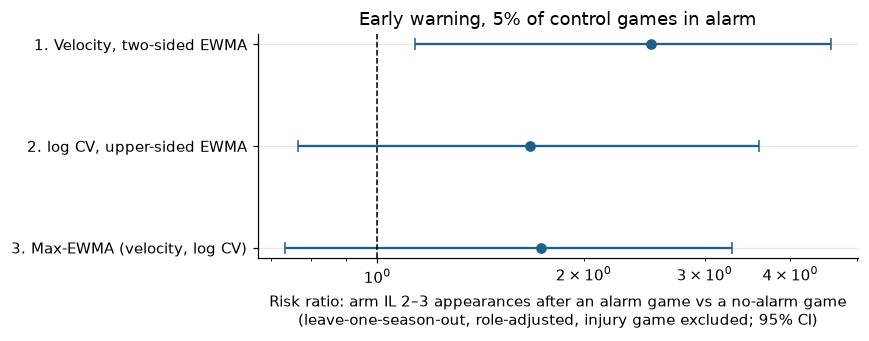

,chart,games,alarms,velocity low,velocity high,variability up
0,"1. Velocity, two-sided EWMA",case games 2-3 before IL,15,12,3,0
1,"1. Velocity, two-sided EWMA",case final games,14,12,2,0
2,"1. Velocity, two-sided EWMA",control games,169,64,105,0
3,"3. Max-EWMA (velocity, log CV)",case games 2-3 before IL,11,10,1,0
4,"3. Max-EWMA (velocity, log CV)",case final games,13,11,2,0
5,"3. Max-EWMA (velocity, log CV)",control games,171,68,97,6


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(comparison))[::-1]
ax.errorbar(comparison["early-warning RR"], y,
            xerr=[comparison["early-warning RR"] - comparison["RR lower95"],
                  comparison["RR upper95"] - comparison["early-warning RR"]],
            fmt="o", capsize=4, color="#1f5f8b")
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_yticks(y, comparison["chart"])
ax.set_xscale("log")
ax.set_xlabel(f"Risk ratio: arm IL 2–{K_LEAD} appearances after an alarm game vs a no-alarm game\n"
              "(leave-one-season-out, role-adjusted, injury game excluded; 95% CI)")
ax.set_title(f"Early warning, {ALARM_RATE:.0%} of control games in alarm")
fig.tight_layout()
save(fig, "F2_early_warning_by_chart")

COMP_NAME = {1.0: "velocity high", -1.0: "velocity low", 2.0: "variability up", 0.0: "velocity at 0"}
comp_rows = []
for chart in ["velocity", "max"]:
    r = main_rows[chart]
    for label, mask in [(f"case games 2-{K_LEAD} before IL", (r["case"] == 1) & r["back"].between(2, K_LEAD)),
                        ("case final games", (r["case"] == 1) & (r["back"] == 1)),
                        ("control games", r["case"] == 0)]:
        a = r.loc[mask & r["alarm"], "component"].map(COMP_NAME).value_counts()
        comp_rows.append({"chart": CHART_LABEL[chart], "games": label, "alarms": int(a.sum()),
                          **{k: int(a.get(k, 0)) for k in ["velocity low", "velocity high", "variability up"]}})
composition = pd.DataFrame(comp_rows)
composition.to_csv(OUT_DIR / "alarm_composition.csv", index=False)
display(composition)

## 11. Paired comparisons between charts

The three charts are scored on the **same** games, so each pair can be compared directly: the difference in
the share of games in alarm, for case games 2–`K_LEAD` before the IL (higher = more early warnings), cases'
final games (detection) and control games (should be ≈ 0, as all are calibrated to `ALARM_RATE`).
Pitcher-clustered bootstrap intervals.

In [14]:
def paired_diff(ra, rb, k=K_LEAD):
    ra, rb = ra.reset_index(drop=True), rb.reset_index(drop=True)
    assert (ra[["uid", "pos"]].to_numpy() == rb[["uid", "pos"]].to_numpy()).all()
    diff = ra["alarm"].to_numpy(float) - rb["alarm"].to_numpy(float)
    groups, codes = np.unique(ra["pkey"].to_numpy(), return_inverse=True)
    masks = {f"case games 2-{k} before IL": ((ra["case"] == 1) & ra["back"].between(2, k)).to_numpy(),
             "case final games": ((ra["case"] == 1) & (ra["back"] == 1)).to_numpy(),
             "control games": (ra["case"] == 0).to_numpy()}
    rng = np.random.default_rng(SEED)
    W = np.array([np.bincount(rng.integers(len(groups), size=len(groups)), minlength=len(groups))
                  for _ in range(N_BOOT)], float)[:, codes]
    out = []
    for name, m in masks.items():
        if not m.any():
            continue
        boot = (W[:, m] * diff[m]).sum(axis=1) / np.maximum(W[:, m].sum(axis=1), 1e-12)
        out.append({"games": name, "difference": diff[m].mean(), "lower95": np.nanpercentile(boot, 2.5),
                    "upper95": np.nanpercentile(boot, 97.5)})
    return out


pair_rows = []
for a, b in [("max", "velocity"), ("max", "variability"), ("velocity", "variability")]:
    for r in paired_diff(main_rows[a], main_rows[b]):
        pair_rows.append({"comparison": f"{CHART_LABEL[a]}  minus  {CHART_LABEL[b]}", **r})
paired = pd.DataFrame(pair_rows)
paired.to_csv(OUT_DIR / "chart_paired_differences.csv", index=False)
with pd.option_context("display.max_colwidth", 80):
    display(paired.round(3))

,comparison,games,difference,lower95,upper95
0,"3. Max-EWMA (velocity, log CV) minus 1. Velocity, two-sided EWMA",case games 2-3 before IL,-0.032,-0.075,0.000
1,"3. Max-EWMA (velocity, log CV) minus 1. Velocity, two-sided EWMA",case final games,-0.014,-0.048,0.000
2,"3. Max-EWMA (velocity, log CV) minus 1. Velocity, two-sided EWMA",control games,0.001,-0.004,0.006
3,"3. Max-EWMA (velocity, log CV) minus 2. log CV, upper-sided EWMA",case games 2-3 before IL,-0.032,-0.107,0.035
4,"3. Max-EWMA (velocity, log CV) minus 2. log CV, upper-sided EWMA",case final games,0.042,-0.070,0.159
5,"3. Max-EWMA (velocity, log CV) minus 2. log CV, upper-sided EWMA",control games,-0.011,-0.045,0.019
6,"1. Velocity, two-sided EWMA minus 2. log CV, upper-sided EWMA",case games 2-3 before IL,0.000,-0.070,0.061
7,"1. Velocity, two-sided EWMA minus 2. log CV, upper-sided EWMA",case final games,0.056,-0.048,0.169
8,"1. Velocity, two-sided EWMA minus 2. log CV, upper-sided EWMA",control games,-0.012,-0.049,0.021


In [20]:
# POST HOC: lower-sided velocity EWMA (chosen after seeing Section 10). Same LOSO procedure and alarm budget.
if "_chart_statistic_orig" not in globals():
    _chart_statistic_orig = chart_statistic

def chart_statistic(Vu, chart, lam):
    if chart == "velocity_low":
        zv = ewma(Vu["velo"], lam) / ewma_sd(len(Vu["velo"]), lam)
        return np.maximum(-zv, 0), np.full(len(zv), -1.0)
    return _chart_statistic_orig(Vu, chart, lam)

CHART_LABEL["velocity_low"] = "1b. Velocity, lower-sided EWMA (post hoc)"
rows_lo, picks_lo, frozen_lo = run_loso(V_MAIN, train_uids, labels_main, charts=["velocity", "velocity_low"])
display(pd.DataFrame([{"chart": CHART_LABEL[c], **summarise(rows_lo[c])} for c in ["velocity", "velocity_low"]]).round(3))
print("Paired: lower-sided minus two-sided")
display(pd.DataFrame(paired_diff(rows_lo["velocity_low"], rows_lo["velocity"])).round(3))
display(frozen_lo.round(3))

,chart,cases,control games in alarm,case games 2-3 before IL in alarm,early-warning RR,RR lower95,RR upper95,final game in alarm,early-warning sensitivity (unit),matched specificity (unit)
0,"1. Velocity, two-sided EWMA",97,0.051,0.121,2.508,1.134,4.578,0.197,0.213,0.913
1,"1b. Velocity, lower-sided EWMA (post hoc)",97,0.050,0.121,2.528,1.269,4.123,0.197,0.169,0.897


Paired: lower-sided minus two-sided


,games,difference,lower95,upper95
0,case games 2-3 before IL,0.0,-0.053,0.043
1,case final games,0.0,-0.069,0.066
2,control games,-0.0,-0.021,0.019


,chart,lambda,L,train_early_warning_hit_rate
0,velocity,0.55,3.956,0.105
1,velocity_low,0.55,3.165,0.145


## 12. Time from first signal to the subsequent arm IL

For cases whose chart signalled before the IL (leave-one-season-out rows): appearances from the first
alarm through his final game (1 = the alarm came in the final game) and days from the alarm game to the IL.

In [16]:
lead_rows = []
for chart in CHARTS:
    r = main_rows[chart]
    for u, g in r.loc[(r["case"] == 1) & r["alarm"]].groupby("uid"):
        first = g.sort_values("pos").iloc[0]
        lead_rows.append({"chart": CHART_LABEL[chart], "uid": u, "appearances_before_IL": int(first["back"]),
                          "days_before_IL": (units.at[u, "event_date"] - pd.Timestamp(first["date"])).days})
lead_time = pd.DataFrame(lead_rows, columns=["chart", "uid", "appearances_before_IL", "days_before_IL"])
lead_time.to_csv(OUT_DIR / "time_to_signal.csv", index=False)
if len(lead_time):
    display(lead_time.groupby("chart")[["appearances_before_IL", "days_before_IL"]]
                     .describe()[[("appearances_before_IL", "count"), ("appearances_before_IL", "50%"),
                                  ("appearances_before_IL", "75%"), ("days_before_IL", "50%"),
                                  ("days_before_IL", "75%")]].round(1))

appearances_before_IL             \
                                               count  50%   75%   
chart                                                             
1. Velocity, two-sided EWMA                     26.0  3.5   9.5   
2. log CV, upper-sided EWMA                     15.0  6.0  11.0   
3. Max-EWMA (velocity, log CV)                  27.0  4.0  11.0   

                               days_before_IL        
                                          50%   75%  
chart                                                
1. Velocity, two-sided EWMA              16.0  35.2  
2. log CV, upper-sided EWMA              30.0  38.0  
3. Max-EWMA (velocity, log CV)           19.0  36.5

## 13. Sensitivity analyses (training seasons, leave-one-season-out)

Each row repeats Section 9 in full (calibration and λ selection inside the folds) under one change:

| Variant | Change |
|---|---|
| alarm budget 3% / 10% | `ALARM_RATE` |
| early-warning window 2–5 | IL 2–5 appearances ahead |
| one unit per pitcher | earliest training season per pitcher only (removes repeat pitchers) |
| elbow → elbow | initial elbow IL only; case = subsequent elbow IL |
| CV from first 20 fastballs | variability from each game's first `FIRST_N_FB` primary fastballs |
| residual CV | variability around the game's own linear fade (removes normal fatigue) |
| ≥ 12 fastballs per game | stricter minimum for a game to count |
| post-return baseline | μ₀ from his first 3 monitored games; monitoring starts at game 4 |
| starters / relievers | subgroups of the main run (same thresholds) |

done: main
done: alarm budget 3%
done: alarm budget 10%
done: early-warning window 2-5
done: one unit per pitcher
done: elbow -> elbow
done: CV from first 20 fastballs
done: residual CV (fade removed)
done: >= 12 fastballs per game
done: post-return baseline (first 3 games)


,variant,chart,cases,control games in alarm,lead games in alarm,early-warning RR,RR lower95,RR upper95,final game in alarm,early-warning sensitivity (unit),matched specificity (unit),lead games in alarm (2-5)
0,main,"1. Velocity, two-sided EWMA",97,0.051,0.121,2.508,1.134,4.578,0.197,0.213,0.913,NaN
1,main,"2. log CV, upper-sided EWMA",97,0.063,0.121,1.672,0.767,3.602,0.141,0.157,0.916,NaN
2,main,"3. Max-EWMA (velocity, log CV)",97,0.051,0.089,1.730,0.734,3.287,0.183,0.225,0.897,NaN
3,alarm budget 3%,"1. Velocity, two-sided EWMA",97,0.032,0.073,2.195,0.804,4.174,0.141,0.169,0.923,NaN
4,alarm budget 3%,"2. log CV, upper-sided EWMA",97,0.038,0.048,1.012,0.154,2.893,0.085,0.056,0.957,NaN
5,alarm budget 3%,"3. Max-EWMA (velocity, log CV)",97,0.031,0.056,1.732,0.603,3.511,0.141,0.157,0.915,NaN
6,alarm budget 10%,"1. Velocity, two-sided EWMA",97,0.101,0.153,1.601,0.785,2.684,0.183,0.258,0.839,NaN
7,alarm budget 10%,"2. log CV, upper-sided EWMA",97,0.106,0.169,1.476,0.776,2.681,0.183,0.247,0.782,NaN
8,alarm budget 10%,"3. Max-EWMA (velocity, log CV)",97,0.105,0.194,1.978,1.092,3.272,0.211,0.315,0.765,NaN
9,early-warning window 2-5,"1. Velocity, two-sided EWMA",97,0.051,NaN,1.693,0.765,3.014,0.183,0.225,0.911,0.088


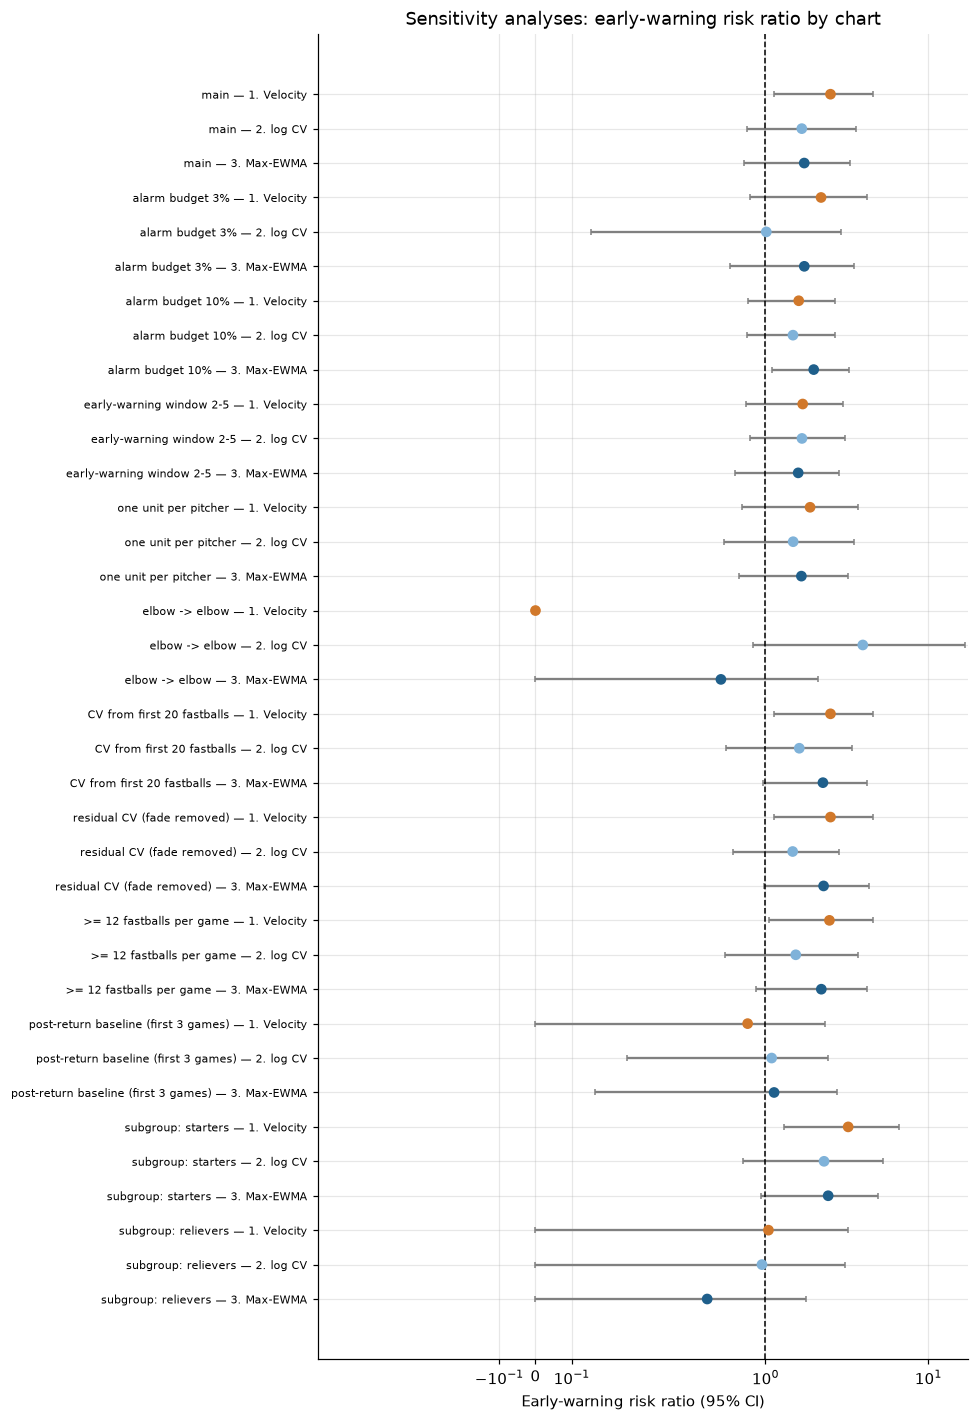

In [17]:
first_unit = units.loc[train_uids].sort_values("Season").groupby("pkey")["uid"].first().tolist()
elbow_initial = [u for u in train_uids if PATTERNS["elbow"].search(str(units.at[u, "initial_injury"]))]
labels_elbow = {u: int(units.at[u, "case"] == 1 and bool(PATTERNS["elbow"].search(str(units.at[u, "next_injury"]))))
                for u in all_uids}

variants = [  # name, inputs, uids, labels, alarm rate, window
    ("main", V_MAIN, train_uids, labels_main, ALARM_RATE, K_LEAD),
    ("alarm budget 3%", V_MAIN, train_uids, labels_main, 0.03, K_LEAD),
    ("alarm budget 10%", V_MAIN, train_uids, labels_main, 0.10, K_LEAD),
    ("early-warning window 2-5", V_MAIN, train_uids, labels_main, ALARM_RATE, 5),
    ("one unit per pitcher", V_MAIN, first_unit, labels_main, ALARM_RATE, K_LEAD),
    ("elbow -> elbow", V_MAIN, elbow_initial, labels_elbow, ALARM_RATE, K_LEAD),
    ("CV from first 20 fastballs", build_inputs("logcv_f20")[0], train_uids, labels_main, ALARM_RATE, K_LEAD),
    ("residual CV (fade removed)", build_inputs("logcv_resid")[0], train_uids, labels_main, ALARM_RATE, K_LEAD),
    (">= 12 fastballs per game", build_inputs("logcv", min_fb=12)[0], train_uids, labels_main, ALARM_RATE, K_LEAD),
    ("post-return baseline (first 3 games)", build_inputs("logcv", post_return_n=3)[0], train_uids, labels_main,
     ALARM_RATE, K_LEAD),
]
sens_rows = []
for name, V, uids, labels, rate, k in variants:
    rows, _, _ = (main_rows, None, None) if name == "main" else run_loso(V, uids, labels, rate, k)
    for c in CHARTS:
        sens_rows.append({"variant": name, "chart": CHART_LABEL[c], **summarise(rows[c], k)})
    print("done:", name)
for name, role in [("subgroup: starters", "starter"), ("subgroup: relievers", "reliever")]:
    for c in CHARTS:
        sub = main_rows[c].loc[main_rows[c]["role"] == role]
        if sub["case"].sum():
            sens_rows.append({"variant": name, "chart": CHART_LABEL[c], **summarise(sub)})
sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(OUT_DIR / "chart_sensitivity.csv", index=False)
show = sensitivity.rename(columns={f"case games 2-{K_LEAD} before IL in alarm": "lead games in alarm",
                                   "case games 2-5 before IL in alarm": "lead games in alarm (2-5)"})
with pd.option_context("display.max_rows", 200, "display.width", 250):
    display(show.round(3))

fig, ax = plt.subplots(figsize=(9, 0.32 * len(sensitivity) + 1.5))
order = sensitivity.reset_index(drop=True)
yy = np.arange(len(order))[::-1]
colors = {CHART_LABEL["velocity"]: "#d1782a", CHART_LABEL["variability"]: "#7fb2d9", CHART_LABEL["max"]: "#1f5f8b"}
ax.errorbar(order["early-warning RR"], yy, xerr=[(order["early-warning RR"] - order["RR lower95"]).clip(lower=0),
                                                 (order["RR upper95"] - order["early-warning RR"]).clip(lower=0)],
            fmt="none", ecolor="grey", capsize=2)
ax.scatter(order["early-warning RR"], yy, c=order["chart"].map(colors), zorder=3)
ax.set_yticks(yy, [f"{v} — {SHORT_OF_LABEL[c]}" for v, c in zip(order["variant"], order["chart"])], fontsize=7)
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_xscale("symlog", linthresh=0.5)
ax.set_xlabel("Early-warning risk ratio (95% CI)")
ax.set_title("Sensitivity analyses: early-warning risk ratio by chart")
fig.tight_layout()
save(fig, "F3_sensitivity")

## 14. Example charts (training seasons, frozen settings)

A case whose Max-EWMA signalled before his subsequent arm IL, and a control with a typical chart. Each
panel shows one chart's plotted statistic with its limit $L$; the orange line is the subsequent IL.

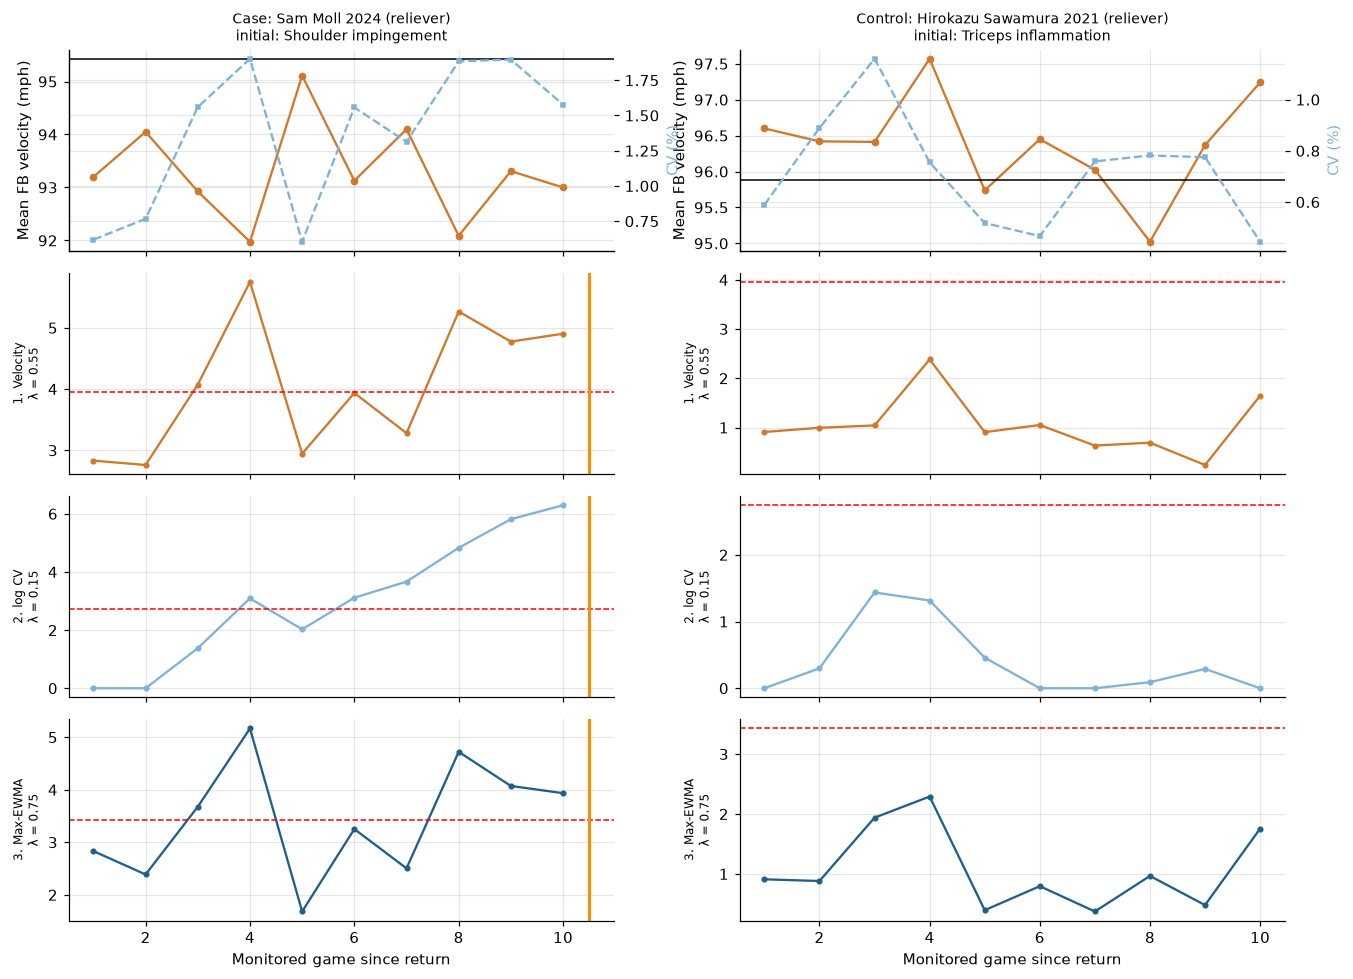

In [18]:
fz = frozen.set_index("chart")
cands = [u for u in train_uids if u in V_MAIN and units.at[u, "case"] == 1
         and (chart_statistic(V_MAIN[u], "max", fz.at["max", "lambda"])[0][V_MAIN[u]["back"] >= 2]
              > fz.at["max", "L"]).any()]
peaks = {u: chart_statistic(V_MAIN[u], "max", fz.at["max", "lambda"])[0].max()
         for u in train_uids if u in V_MAIN and units.at[u, "case"] == 0}
examples = ([cands[0]] if cands else []) + ([min(peaks, key=lambda u: abs(peaks[u] - np.median(list(peaks.values()))))]
                                            if peaks else [])
if examples:
    fig, axes = plt.subplots(4, len(examples), figsize=(6.2 * len(examples), 9), sharex="col", squeeze=False)
    for col, u in enumerate(examples):
        Vu, x = V_MAIN[u], np.arange(1, len(V_MAIN[u]["velo"]) + 1)
        ax = axes[0, col]
        ax.plot(x, Vu["raw_velo"], "o-", ms=4, color="#d1782a")
        ax.axhline(Vu["mu_v"], color="black", lw=1)
        ax.set_ylabel("Mean FB velocity (mph)")
        ax2 = ax.twinx()
        ax2.plot(x, Vu["raw_cv"], "s--", ms=3, color="#7fb2d9")
        ax2.set_ylabel("CV (%)", color="#7fb2d9")
        kind = "Case" if units.at[u, "case"] else "Control"
        ax.set_title(f"{kind}: {units.at[u, 'Name']} {units.at[u, 'Season']} ({units.at[u, 'role']})\n"
                     f"initial: {units.at[u, 'initial_injury']}", fontsize=9)
        for row, chart in enumerate(CHARTS, start=1):
            stat, _ = chart_statistic(Vu, chart, fz.at[chart, "lambda"])
            a = axes[row, col]
            a.plot(x, stat, "o-", ms=3, color=colors[CHART_LABEL[chart]])
            a.axhline(fz.at[chart, "L"], color="red", ls="--", lw=1)
            a.set_ylabel(CHART_SHORT[chart] + f"\nλ = {fz.at[chart, 'lambda']:.2f}", fontsize=8)
            if units.at[u, "case"]:
                a.axvline(len(x) + 0.5, color="darkorange", lw=2)
        axes[-1, col].set_xlabel("Monitored game since return")
    fig.tight_layout()
    save(fig, "F4_example_charts")

## 15. Held-out season (off by default)

**Note for the write-up:** the held-out season was evaluated once in v3 with earlier chart designs, before
this comparison was specified. Its result for these charts is therefore not a clean confirmation; report it
as such. With about a dozen cases, it is an estimate to compare with training, not a pass/fail test.

Fill `PLAN` with the frozen settings from Section 9 **as written in the analysis plan**, then set
`RUN_HELDOUT = True`. The plan's values are used even if training would now give different ones (a
warning is printed).

In [19]:
PLAN = {   # chart: (lambda, L) — copy from the frozen-settings table into the analysis plan, then here
    "velocity": None,
    "variability": None,
    "max": None,
}

if not RUN_HELDOUT:
    print(f"Held-out season {TEST_SEASON} not evaluated (RUN_HELDOUT = False).")
else:
    missing = [c for c, v in PLAN.items() if v is None]
    if missing:
        raise ValueError(f"Fill PLAN for {missing} from the analysis plan before running the held-out season.")
    for c, (lam, L) in PLAN.items():
        f = frozen.set_index("chart").loc[c]
        if abs(lam - f["lambda"]) > 1e-9 or abs(L - f["L"]) > 0.01:
            print(f"Warning: PLAN[{c!r}] = ({lam}, {L}) but training gives ({f['lambda']}, {f['L']:.3f}). Using the plan.")
    games_te, uids_te = game_table(V_MAIN, test_uids, labels_main)
    held_rows = {}
    for c, (lam, L) in PLAN.items():
        stat, comp = stats_for(V_MAIN, uids_te, c, lam)
        held_rows[c] = games_te.assign(alarm=stat > L, component=comp, stat=stat)
    held = pd.DataFrame([{"chart": CHART_LABEL[c], **summarise(held_rows[c])} for c in CHARTS])
    held["training (LOSO) early-warning RR"] = comparison["early-warning RR"].to_numpy()
    held.to_csv(OUT_DIR / "heldout_chart_comparison.csv", index=False)
    print(f"Held-out season {TEST_SEASON}: {len(uids_te)} units, {int(games_te.groupby('uid')['case'].first().sum())} cases.")
    display(held.round(3))
    hp = pd.DataFrame([{"comparison": f"{CHART_LABEL[a]}  minus  {CHART_LABEL[b]}", **r}
                       for a, b in [("max", "velocity"), ("max", "variability"), ("velocity", "variability")]
                       for r in paired_diff(held_rows[a], held_rows[b])])
    hp.to_csv(OUT_DIR / "heldout_paired_differences.csv", index=False)
    display(hp.round(3))

Held-out season 2026 not evaluated (RUN_HELDOUT = False).


## 16. Notes for interpretation

* **Same alarm cost.** Every chart is calibrated so the same share of control games are in alarm; compare
  them on early warning, detection and the unit-level measures, not on alarm counts.
* **Early warning vs detection.** The early-warning measures exclude the injury game. A chart that only
  lights up in the final game is a detection aid, not a warning.
* **Two-sided velocity.** The evidence for the low side is stronger than for the high side; Section 10
  shows which side produced the alarms, and the paper should say so.
* **Small numbers.** About 20 cases per season; differences between charts within their intervals are not
  differences. The paired comparisons (Section 11) are the direct test.
* **Held-out season.** See Section 15; it was evaluated once before this design was fixed.
* **Earlier work.** The per-game logistic models, the permutation tests and the v2-style EWMA-CUSUM charts
  are in v3.